## Import

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import qutip
from qutip import Bloch, QobjEvo, basis, sesolve, sigmay, sigmaz


## Setup

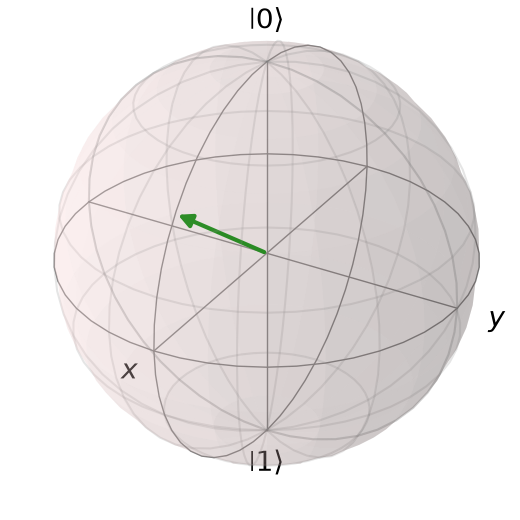

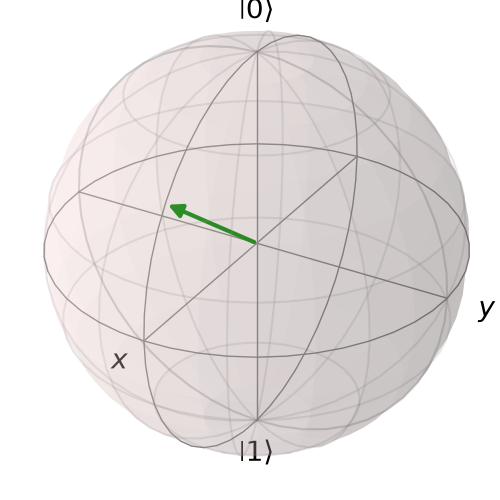

In [23]:
psi = (2.0 * basis(2, 0) + basis(2, 1)).unit()
b = Bloch()
b.add_states(psi)
b.show()

## Simulation with constant magnetic field

.sesolve - solve Schrödinger equation

.mesolve - solve Landbland (master) equation

In [44]:
# simulate the unitary dynamics
H = sigmaz()
times = np.linspace(0, 10, 100)
result = sesolve(H, psi, times, e_ops=[sigmay()])

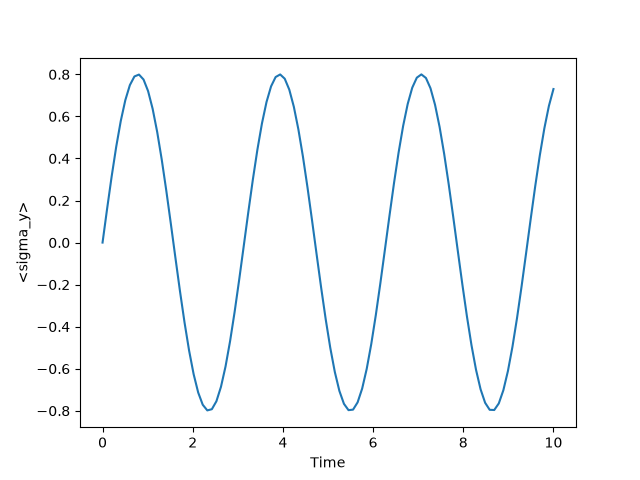

In [45]:
plt.figure() 
plt.plot(times, result.expect[0])
plt.xlabel("Time"), plt.ylabel("<sigma_y>")
plt.show()

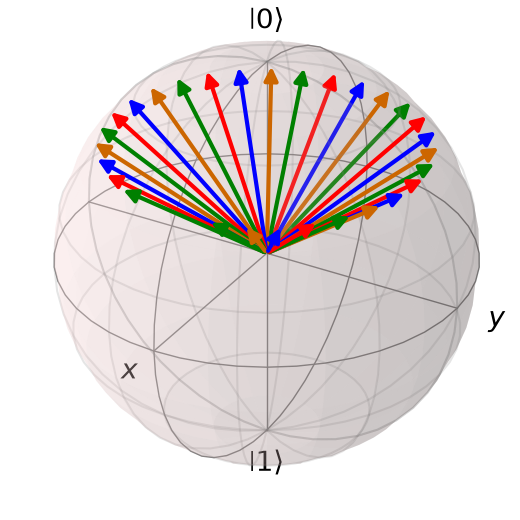

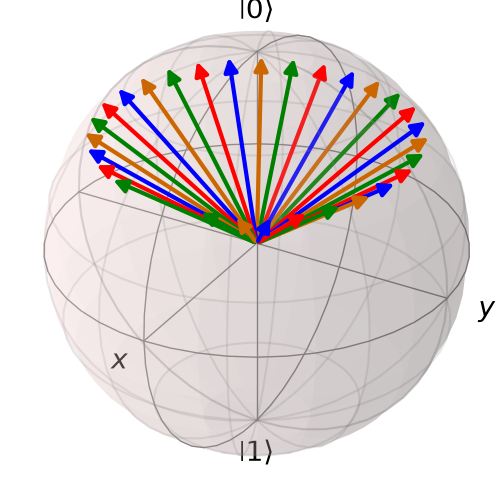

In [30]:
res = sesolve(H, psi, times, e_ops=[])
b = Bloch()
b.add_states(res.states[1:30])
b.show()

## Simulation with varying magnetic field

We may define the magnetic field with a linear and a periodic field strength, and observe the changes in the expecation value of $\sigma_y$

In [39]:
def linear(t, args):
    return 0.3*t

def periodic(t,args):
    return np.cos(0.5*t)

H_lin = QobjEvo([[sigmaz(), linear]], tlist=times)
H_per = QobjEvo([[sigmaz(),periodic]],tlist=times)

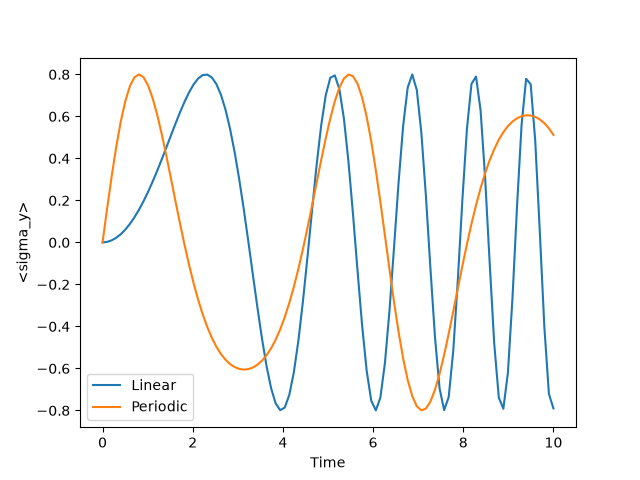

In [43]:
result_lin = sesolve(H_lin, psi, times, e_ops=[sigmay()])
result_per = sesolve(H_per, psi, times, e_ops=[sigmay()])

plt.figure()
plt.plot(times, result_lin.expect[0], label="Linear")
plt.plot(times, result_per.expect[0], label="Periodic")
plt.xlabel("Time"), plt.ylabel("<sigma_y>")
plt.legend()
plt.show()